In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
# Load CSV
players = pd.read_csv("../basketballPlayoffs/players.csv")

In [34]:
 # Check for missing values in each column
print(players.isnull().sum()) 


bioID             0
pos              78
firstseason       0
lastseason        0
height            0
weight            0
college         167
collegeOther    882
birthDate         0
deathDate         0
dtype: int64


In [39]:
# Get the number of unique values for each column
unique_values = players.nunique()

# Display the result
print(unique_values)

bioID           893
pos               7
firstseason       1
lastseason        1
height           21
weight          105
college         160
collegeOther     11
birthDate       764
deathDate         5
dtype: int64


In [44]:
# Count outliers where height or weight is 0
height_outliers_count = (players['height'] == 0).sum()
weight_outliers_count = (players['weight'] == 0).sum()

print(f"Number of height outliers (height == 0): {height_outliers_count}")
print(f"Number of weight outliers (weight == 0): {weight_outliers_count}")


Number of height outliers (height == 0): 80
Number of weight outliers (weight == 0): 119


In [45]:
# Count outliers where birthDate is invalid
players['birthDate'] = pd.to_datetime(players['birthDate'], errors='coerce')
birthDate_outliers_count = players['birthDate'].isna().sum()

print(f"Number of birthDate outliers (invalid dates like '0000-00-00'): {birthDate_outliers_count}")


Number of birthDate outliers (invalid dates like '0000-00-00'): 84


In [46]:
# Count outliers where deathDate is invalid
#players['deathDate'] = pd.to_datetime(players['deathDate'], errors='coerce')
#deathDate_outliers_count = players['deathDate'].isna().sum()

#print(f"Number of deathDate outliers (invalid dates like '0000-00-00'): {deathDate_outliers_count}")


Number of deathDate outliers (invalid dates like '0000-00-00'): 889


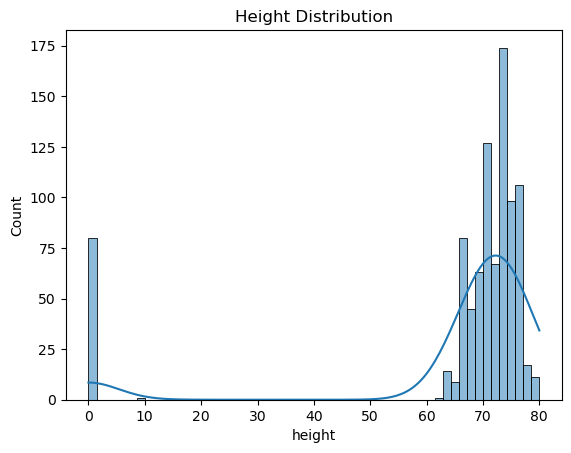

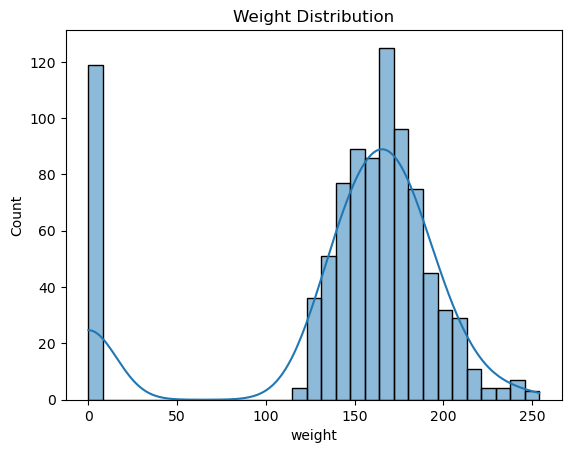

In [35]:
sns.histplot(players['height'], kde=True)
plt.title('Height Distribution')
plt.show()

sns.histplot(players['weight'], kde=True)
plt.title('Weight Distribution')
plt.show()



In [36]:
# Load CSV
players_cleaned = pd.read_csv("../cleaned_datasets/players_cleaned.csv")

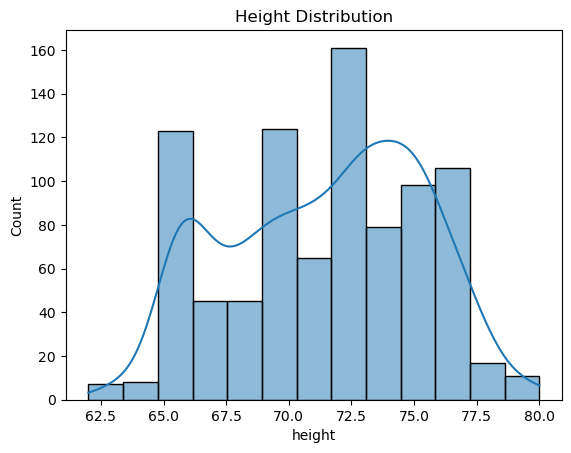

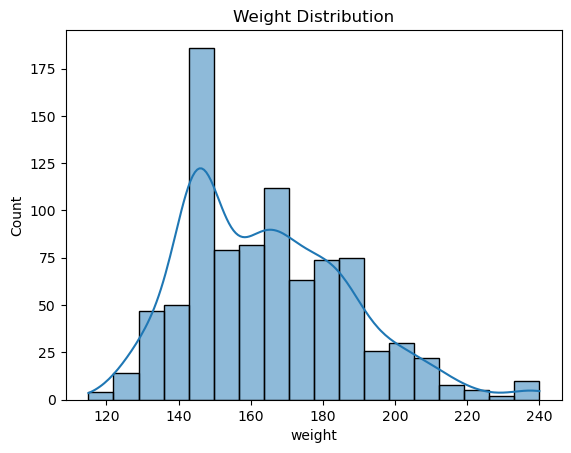

In [37]:
sns.histplot(players_cleaned['height'], kde=True)
plt.title('Height Distribution')
plt.show()

sns.histplot(players_cleaned['weight'], kde=True)
plt.title('Weight Distribution')
plt.show()


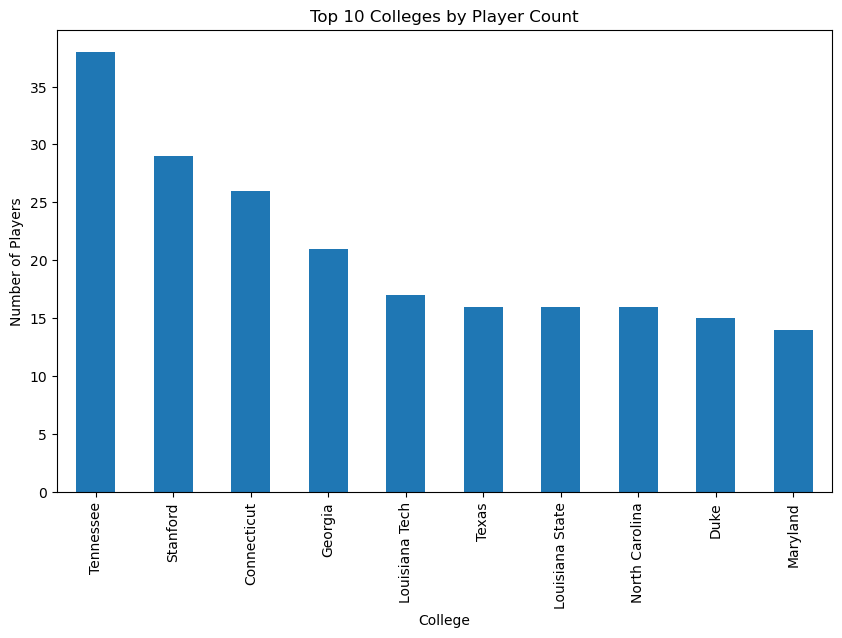

In [38]:
college_counts = players['college'].value_counts().head(10)  # Top 10 colleges
college_counts.plot(kind='bar', figsize=(10, 6))
plt.title('Top 10 Colleges by Player Count')
plt.xlabel('College')
plt.ylabel('Number of Players')
plt.show()


In [47]:
# Split positions where there is a hyphen, and expand to individual positions
players_split_positions = players['pos'].str.split('-', expand=True)

# Flatten the split positions and create a new column to hold the individual positions
positions = players_split_positions.stack().reset_index(drop=True)

# Now 'positions' contains all individual positions
print(positions.value_counts())  # This will give you the count of each position


F    376
G    376
C    209
Name: count, dtype: int64


In [58]:
# Step 1: Split the 'pos' column where there is a hyphen to separate multiple positions
players_split_positions = players['pos'].str.split('-', expand=True)

# Step 2: Count how many positions each player can play (number of columns with non-NA values)
num_positions = players_split_positions.notna().sum(axis=1)

# Step 3: Count how many players have more than 1 positions
players_with_two_positions = num_positions[num_positions > 1]

# Step 4: Display the number of players who can play more than 1 positions
print(f"Number of players who can play exactly two positions: {players_with_two_positions.shape[0]}")

Number of players who can play exactly two positions: 146


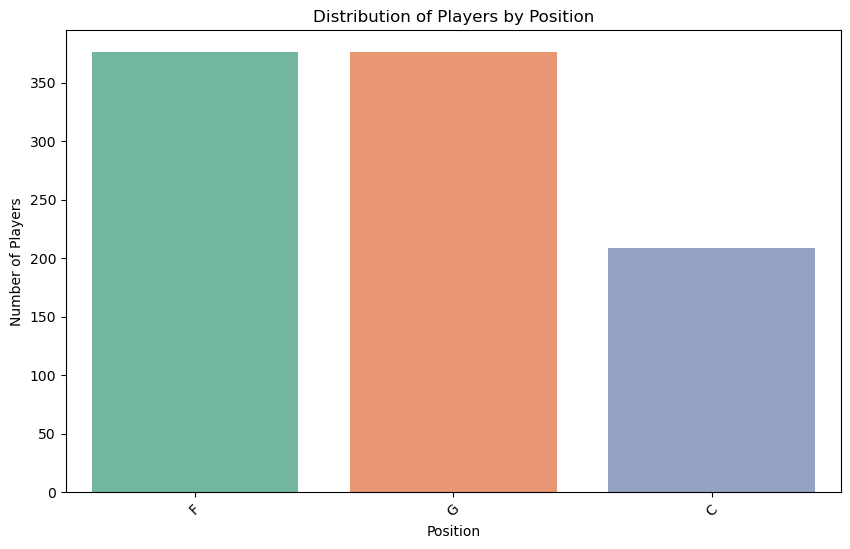

In [49]:
# Plot the distribution of positions
plt.figure(figsize=(10, 6))
sns.barplot(x=positions_counts.index, y=positions_counts.values, palette='Set2')

# Add titles and labels
plt.title('Distribution of Players by Position')
plt.xlabel('Position')
plt.ylabel('Number of Players')
plt.xticks(rotation=45)
plt.show()